Stationarity

ADF Statistic: -18.60059762146653
p-value: 2.06939662875529e-30


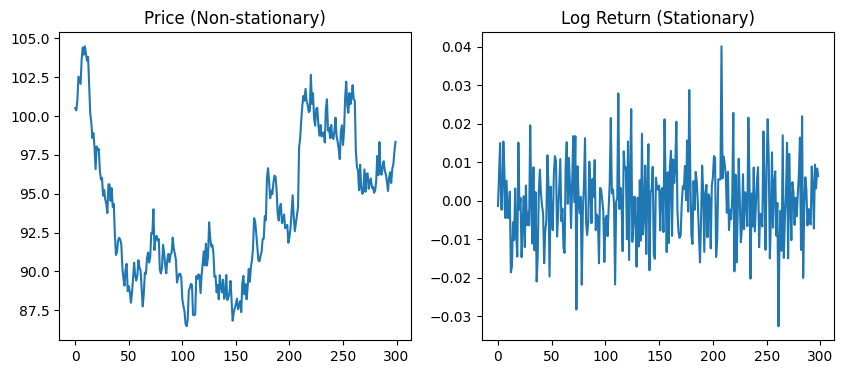

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss

# Fake price series (non-stationary)
np.random.seed(42)
n = 300
eps = np.random.normal(0, 1, n)
price = np.cumsum(eps) + 100  # Random walk with drift

# Log return (stationary candidate)
log_return = np.diff(np.log(price))

# ADF test
adf_stat, p_value, _, _, crit_vals, _ = adfuller(log_return)
print("ADF Statistic:", adf_stat)
print("p-value:", p_value)

# Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(price)
plt.title("Price (Non-stationary)")

plt.subplot(1,2,2)
plt.plot(log_return)
plt.title("Log Return (Stationary)")
plt.show()

Stationarity Test

--- Running ADF Test for: Stationary Series (Treadmill Walker) ---
ADF Statistic: -31.81109384149144
p-value: 0.0
Critical Values:
	1%: -3.4369127451400474
	5%: -2.864437475834273
	10%: -2.568312754566378
Conclusion: Strong evidence against the null hypothesis (H0). Reject H0.
The series is likely stationary.


--- Running ADF Test for: Non-Stationary Series (Mountain Climber) ---
ADF Statistic: -1.7069657856315612
p-value: 0.42752711551181555
Critical Values:
	1%: -3.4369127451400474
	5%: -2.864437475834273
	10%: -2.568312754566378
Conclusion: Weak evidence against null hypothesis (H0). Fail to reject H0.
The series is likely non-stationary.




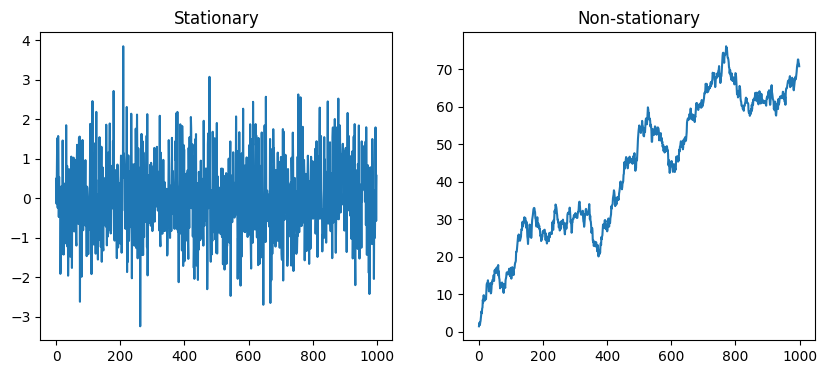

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# --- Setup ---
# Set a seed for reproducibility
np.random.seed(42)

# --- Create Time Series Data ---

# 1. Stationary Series (walking on a treadmill)
# This is just random noise around a mean of 0
stationary_series = np.random.randn(1000)

# 2. Non-Stationary Series (climbing a mountain)
# This is a 'random walk', where each step depends on the last
# It has a clear trend (drifting)
non_stationary_series = np.random.randn(1000).cumsum()

# --- Perform ADF Test ---
def run_adf_test(series, name):
    """
    Runs the Augmented Dickey-Fuller test and prints the results.
    """
    print(f"--- Running ADF Test for: {name} ---")
    # The adfuller function returns several values, we are most interested in the p-value
    result = adfuller(series)
    p_value = result[1]

    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value}')

    # Interpretation
    # H0: The series is non-stationary (has a unit root).
    # H1: The series is stationary.
    if p_value <= 0.05:
        print("Conclusion: Strong evidence against the null hypothesis (H0). Reject H0.")
        print("The series is likely stationary.")
    else:
        print("Conclusion: Weak evidence against null hypothesis (H0). Fail to reject H0.")
        print("The series is likely non-stationary.")
    print("\n")


# Run tests on both series
run_adf_test(stationary_series, "Stationary Series (Treadmill Walker)")
run_adf_test(non_stationary_series, "Non-Stationary Series (Mountain Climber)")
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(stationary_series)
plt.title("Stationary")

plt.subplot(1,2,2)
plt.plot(non_stationary_series)
plt.title("Non-stationary")
plt.show()

Non-stationary

ADF Statistic: -1.9083972870386328
p-value: 0.3281211322254144
After differencing - ADF Statistic: -18.58949062660009
After differencing - p-value: 2.0741473695115225e-30


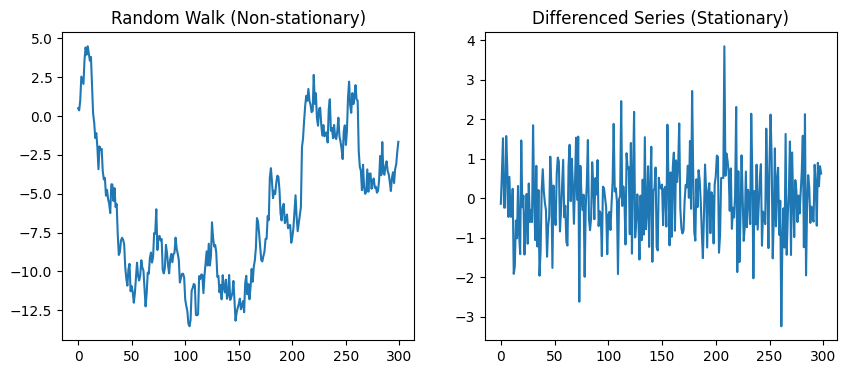

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Random walk (non-stationary)
np.random.seed(42)
n = 300
eps = np.random.normal(0,1,n)
X = np.cumsum(eps)  # Random walk

# ADF test
adf_stat, p_value, _, _, crit_vals, _ = adfuller(X)
print("ADF Statistic:", adf_stat)
print("p-value:", p_value)

# Differencing
Y = np.diff(X)

# ADF test after differencing
adf_stat, p_value, _, _, crit_vals, _ = adfuller(Y)
print("After differencing - ADF Statistic:", adf_stat)
print("After differencing - p-value:", p_value)

# Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(X)
plt.title("Random Walk (Non-stationary)")

plt.subplot(1,2,2)
plt.plot(Y)
plt.title("Differenced Series (Stationary)")
plt.show()


ARMA Model

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  500
Model:                 ARIMA(2, 0, 1)   Log Likelihood                -700.049
Date:                Thu, 04 Sep 2025   AIC                           1410.097
Time:                        09:56:14   BIC                           1431.170
Sample:                             0   HQIC                          1418.366
                                - 500                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0147      0.109      0.134      0.893      -0.200       0.229
ar.L1          0.6841      0.070      9.790      0.000       0.547       0.821
ar.L2         -0.2991      0.061     -4.930      0.0

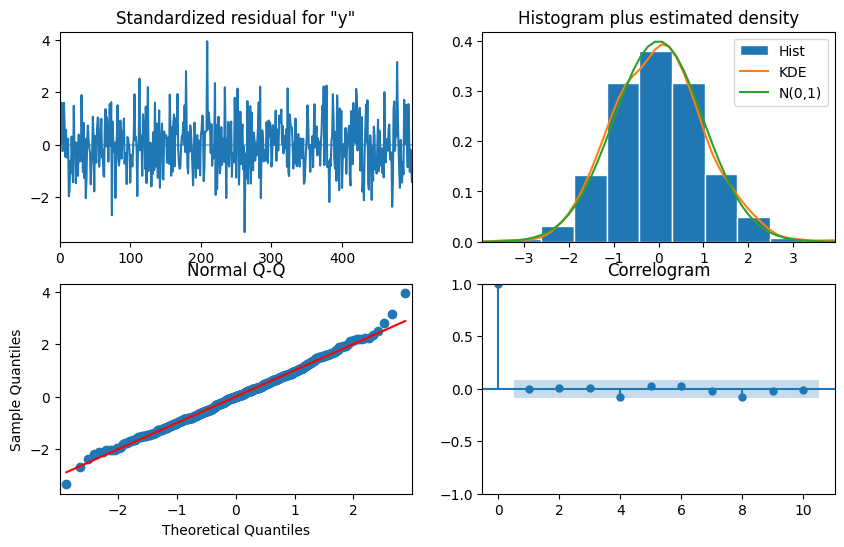

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Fake data (white noise + AR structure)
np.random.seed(42)
n = 500
eps = np.random.normal(0, 1, n)
X = np.zeros(n)
for t in range(2, n):
    X[t] = 0.7*X[t-1] - 0.3*X[t-2] + eps[t] + 0.5*eps[t-1]

# Fit ARMA(2,1)
model = ARIMA(X, order=(2,0,1))
res = model.fit()

print(res.summary())
res.plot_diagnostics(figsize=(10,6))
plt.show()


Cointegration

Cointegration test p-value: 0.5567274710544523


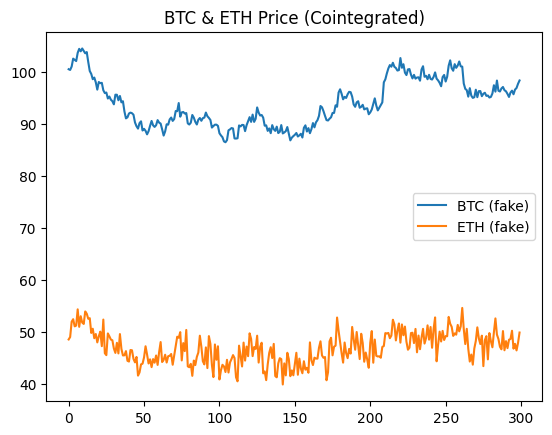

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint

# Fake BTC & ETH prices
np.random.seed(42)
n = 300
btc = np.cumsum(np.random.normal(0,1,n)) + 100
eth = btc * 0.5 + np.random.normal(0,2,n)  # cointegrated with btc

# Engle-Granger cointegration test
score, p_value, _ = coint(btc, eth)
print("Cointegration test p-value:", p_value)

# Plot
plt.plot(btc, label="BTC (fake)")
plt.plot(eth, label="ETH (fake)")
plt.legend()
plt.title("BTC & ETH Price (Cointegrated)")
plt.show()

Before differencing - p-value: 0.3281211322254144
After differencing - p-value: 2.0741473695115225e-30


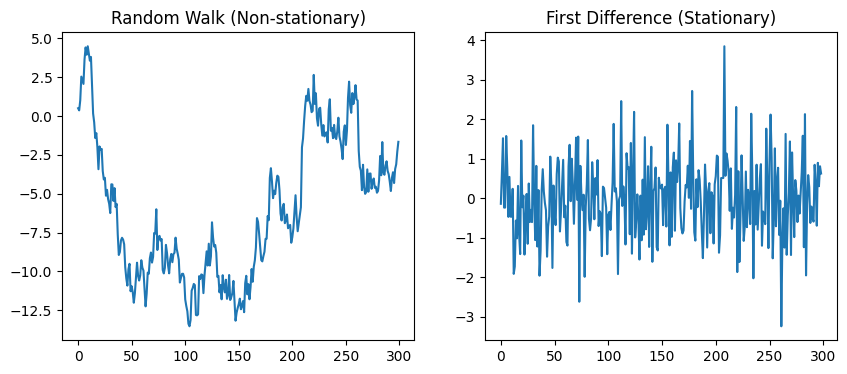

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Random walk (non-stationary)
np.random.seed(42)
n = 300
eps = np.random.normal(0,1,n)
X = np.cumsum(eps)  # Random walk

# ADF test before differencing
adf_stat, p_value, _, _, _, _ = adfuller(X)
print("Before differencing - p-value:", p_value)

# First differencing
Y = np.diff(X)

# ADF test after differencing
adf_stat, p_value, _, _, _, _ = adfuller(Y)
print("After differencing - p-value:", p_value)

# Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(X)
plt.title("Random Walk (Non-stationary)")

plt.subplot(1,2,2)
plt.plot(Y)
plt.title("First Difference (Stationary)")
plt.show()


kiểm tra lợi nhuận trung bình của một chiến lược có khác 0.

t-statistic: -0.593
p-value: 0.5546
Fail to reject H0: no significant difference


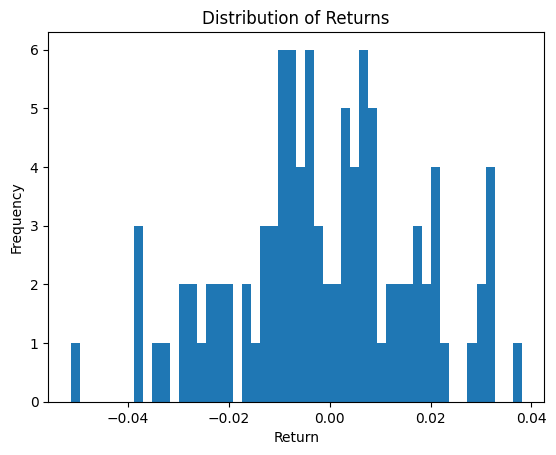

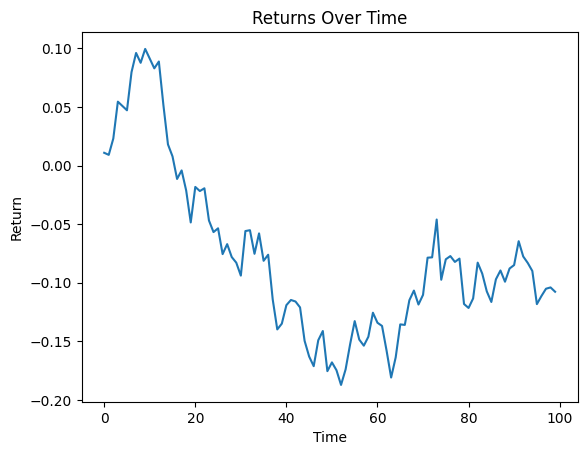

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

np.random.seed(42)
# Giả lập returns ~ Normal(0.001, 0.02)
returns = np.random.normal(0.001, 0.02, 100)

# One-sample t-test: H0: mean = 0
t_stat, p_value = stats.ttest_1samp(returns, 0)

print("t-statistic:", round(t_stat,3))
print("p-value:", round(p_value,4))

if p_value < 0.05:
    print("Reject H0: mean return is significantly different from 0")
else:
    print("Fail to reject H0: no significant difference")

plt.hist(returns, bins=50)
plt.title("Distribution of Returns")
plt.xlabel("Return")
plt.ylabel("Frequency")
plt.show()

plt.plot(np.cumsum(returns))
plt.title("Returns Over Time")
plt.xlabel("Time")
plt.ylabel("Return")
plt.show()

kiểm định lợi nhuận trung bình có khác 0 không bằng z-Test.

z-statistic: 2.239
p-value: 0.0252
Reject H0: mean return is significantly different from 0


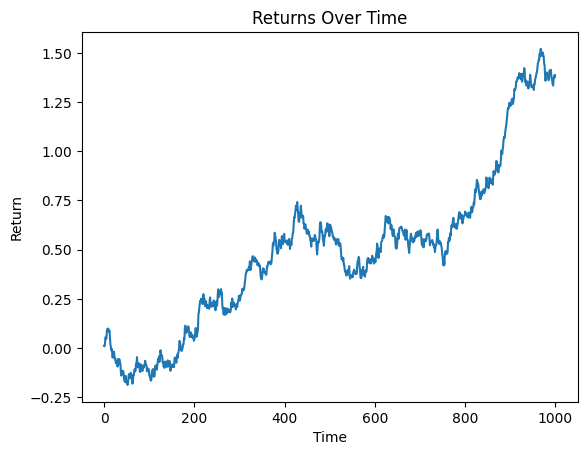

In [ ]:
import numpy as np
from statsmodels.stats.weightstats import ztest
import matplotlib.pyplot as plt

np.random.seed(42)
# Giả lập returns ~ Normal(0.001, 0.02)
returns = np.random.normal(0.001, 0.02, 1000)

# One-sample z-test: H0: mean = 0
z_stat, p_value = ztest(returns, value=0)

print("z-statistic:", round(z_stat,3))
print("p-value:", round(p_value,4))

if p_value < 0.05:
    print("Reject H0: mean return is significantly different from 0")
else:
    print("Fail to reject H0: no significant difference")

plt.plot(np.cumsum(returns))
plt.title("Returns Over Time")
plt.xlabel("Time")
plt.ylabel("Return")
plt.show()


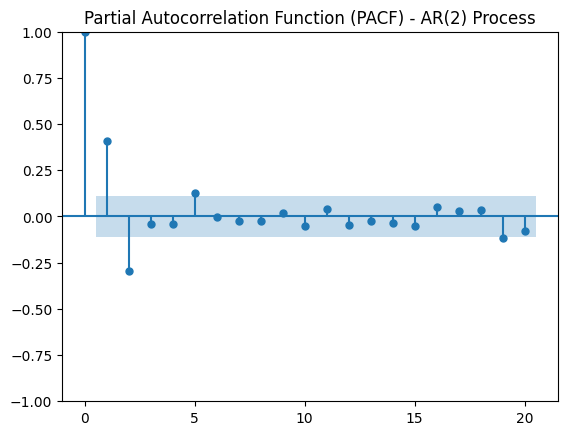

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf

np.random.seed(42)
n = 300

# AR(2): y_t = 0.6*y_{t-1} - 0.3*y_{t-2} + e_t
y = [0, 0]
for t in range(2, n):
    y.append(0.6*y[-1] - 0.3*y[-2] + np.random.normal())

plot_pacf(y, lags=20, method='ywm')
plt.title("Partial Autocorrelation Function (PACF) - AR(2) Process")
plt.show()


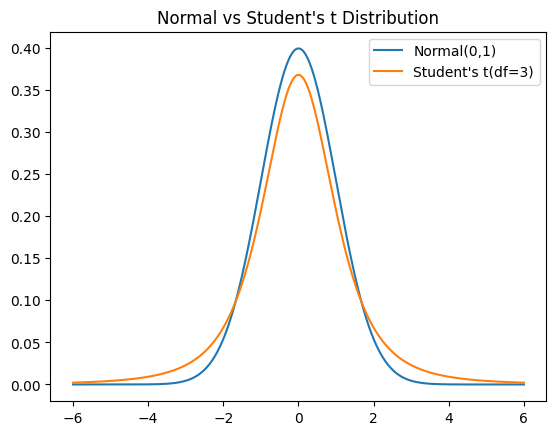

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st

x = np.linspace(-6, 6, 500)
pdf_normal = st.norm.pdf(x, 0, 1)
pdf_t = st.t.pdf(x, df=3)

plt.plot(x, pdf_normal, label="Normal(0,1)")
plt.plot(x, pdf_t, label="Student's t(df=3)")
plt.title("Normal vs Student's t Distribution")
plt.legend()
plt.show()
